# BRFSS Model [Target: MENTHLTH]

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os
import time
import re
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.feature_selection import SelectFromModel

from sklearn.linear_model import Ridge, Lasso, LinearRegression, PoissonRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from tabicl import TabICLClassifier, TabICLRegressor
from lightgbm import LGBMRegressor

## Load

In [2]:
# ============================================================
# BRFSS Model Training Notebook
# Loads preprocessed data and trains multiple models
# ============================================================

# ============================================================
# Configuration
# ============================================================
n_samples = 79998
classic_models_n_samples = 40000
deep_models_n_samples = 50000
n_years = 3
target = "MENTHLTH"
random_state = 42
test_size = 0.20
n_important_features = 40
dataset = f"{n_years}-years_{n_samples}-samples_{n_important_features}-features_{target}-target.csv"
dataset_path = os.path.join("data/preprocessed", dataset)

if not os.path.exists(dataset_path):
    raise FileNotFoundError(
        f"Preprocessed file not found: {dataset_path}\n"
        f"Please run the preprocessing notebook first to generate this file."
    )

# Load the data
df = pd.read_csv(dataset_path)
print(f"Loaded {len(df)} rows, {len(df.columns)} columns from '{dataset}'")

# Extract actual number of years from the data
if 'YEAR' in df.columns:
    actual_years = sorted(df['YEAR'].unique())
    print(f"Years included: {actual_years}")

# ============================================================
# Prepare Features and Target
# ============================================================

# Ensure target is in the dataframe
if target not in df.columns:
    raise ValueError(f"Target '{target}' not found in dataframe")

# Remove ID columns
drop_cols = [
    target,
    "SEQNO",
    "_PSU",
    "_STSTR",
    "IDATE",
    "IMONTH",
    "IDAY",
    "IYEAR"
]

X = df.drop(columns=[c for c in drop_cols if c in df.columns], errors="ignore")

# Remove leakage columns
if target == "MENTHLTH":
    leakage = ["_MENT14D", "POORHLTH"]
elif target == "PHYSHLTH":
    leakage = ["_PHYS14D"]
elif target == "GENHLTH":
    leakage = ["_RFHLTH"]
elif target == "LSATISFY":
    leakage = []
else:
    leakage = []

X = X.drop(columns=[c for c in leakage if c in X.columns], errors="ignore")

# ============================================================
# OPTIONAL: Drop survey design variables (to avoid leakage)
# These are weighting variables, not health predictors
# ============================================================
survey_design_vars = ['_LLCPWT', '_LLCPWT2', '_STRWT', '_WT2RAKE', '_RAWRAKE']
X = X.drop(columns=[c for c in survey_design_vars if c in X.columns], errors="ignore")
print(f"Dropped survey design variables: {[c for c in survey_design_vars if c in X.columns]}")

# Store y (target)
y = df[target]

print(f"Samples: {y.shape[0]}\nFeatures: {X.shape[1]}")

# ============================================================
# Train-Test Split
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X[:classic_models_n_samples], y[:classic_models_n_samples],
    test_size=test_size,
    random_state=random_state
)

print(f"\nTraining set: {len(X_train)} samples")
print(f"Test set: {len(X_test)} samples")

# ============================================================
# Feature Scaling (for linear models)
# ============================================================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Loaded 79998 rows, 41 columns from '3-years_79998-samples_40-features_MENTHLTH-target.csv'
Dropped survey design variables: []
Samples: 79998
Features: 40

Training set: 32000 samples
Test set: 8000 samples


In [3]:
for i in range(31):
    print(f"{int(len(np.where(y == i)[0]) / len(y) * 100)}% of targets are {i}")

60% of targets are 0
3% of targets are 1
5% of targets are 2
3% of targets are 3
1% of targets are 4
4% of targets are 5
0% of targets are 6
1% of targets are 7
0% of targets are 8
0% of targets are 9
3% of targets are 10
0% of targets are 11
0% of targets are 12
0% of targets are 13
0% of targets are 14
3% of targets are 15
0% of targets are 16
0% of targets are 17
0% of targets are 18
0% of targets are 19
2% of targets are 20
0% of targets are 21
0% of targets are 22
0% of targets are 23
0% of targets are 24
0% of targets are 25
0% of targets are 26
0% of targets are 27
0% of targets are 28
0% of targets are 29
6% of targets are 30


---

## Model

### Traditional tree-based models


MODEL TRAINING AND EVALUATION

Training: XGBoost
Hyperparameter tuning with RandomizedSearchCV...
Best parameters: {'colsample_bytree': 0.7, 'learning_rate': 0.02, 'max_depth': 3, 'min_child_weight': 3, 'n_estimators': 650, 'reg_alpha': 0.1, 'reg_lambda': 0.1, 'subsample': 0.7}
Cross-Validation MAE: 4.1411 (+/- 0.0653)

Test Set Performance:
  MAE:  4.1112
  RMSE: 6.6932
  R²:   0.3560

Training: Random Forest
Hyperparameter tuning with RandomizedSearchCV...
Best parameters: {'max_depth': 10, 'min_samples_leaf': 6, 'min_samples_split': 2, 'n_estimators': 750}
Cross-Validation MAE: 4.2059 (+/- 0.0743)

Test Set Performance:
  MAE:  4.1531
  RMSE: 6.7366
  R²:   0.3477

Training: LightGBM
Hyperparameter tuning with RandomizedSearchCV...
Best parameters: {'learning_rate': 0.02, 'max_depth': 7, 'n_estimators': 500}
Cross-Validation MAE: 4.2328 (+/- 0.0611)

Test Set Performance:
  MAE:  4.1645
  RMSE: 6.6978
  R²:   0.3552

Training: Linear Regression
Hyperparameter tuning with Randomized

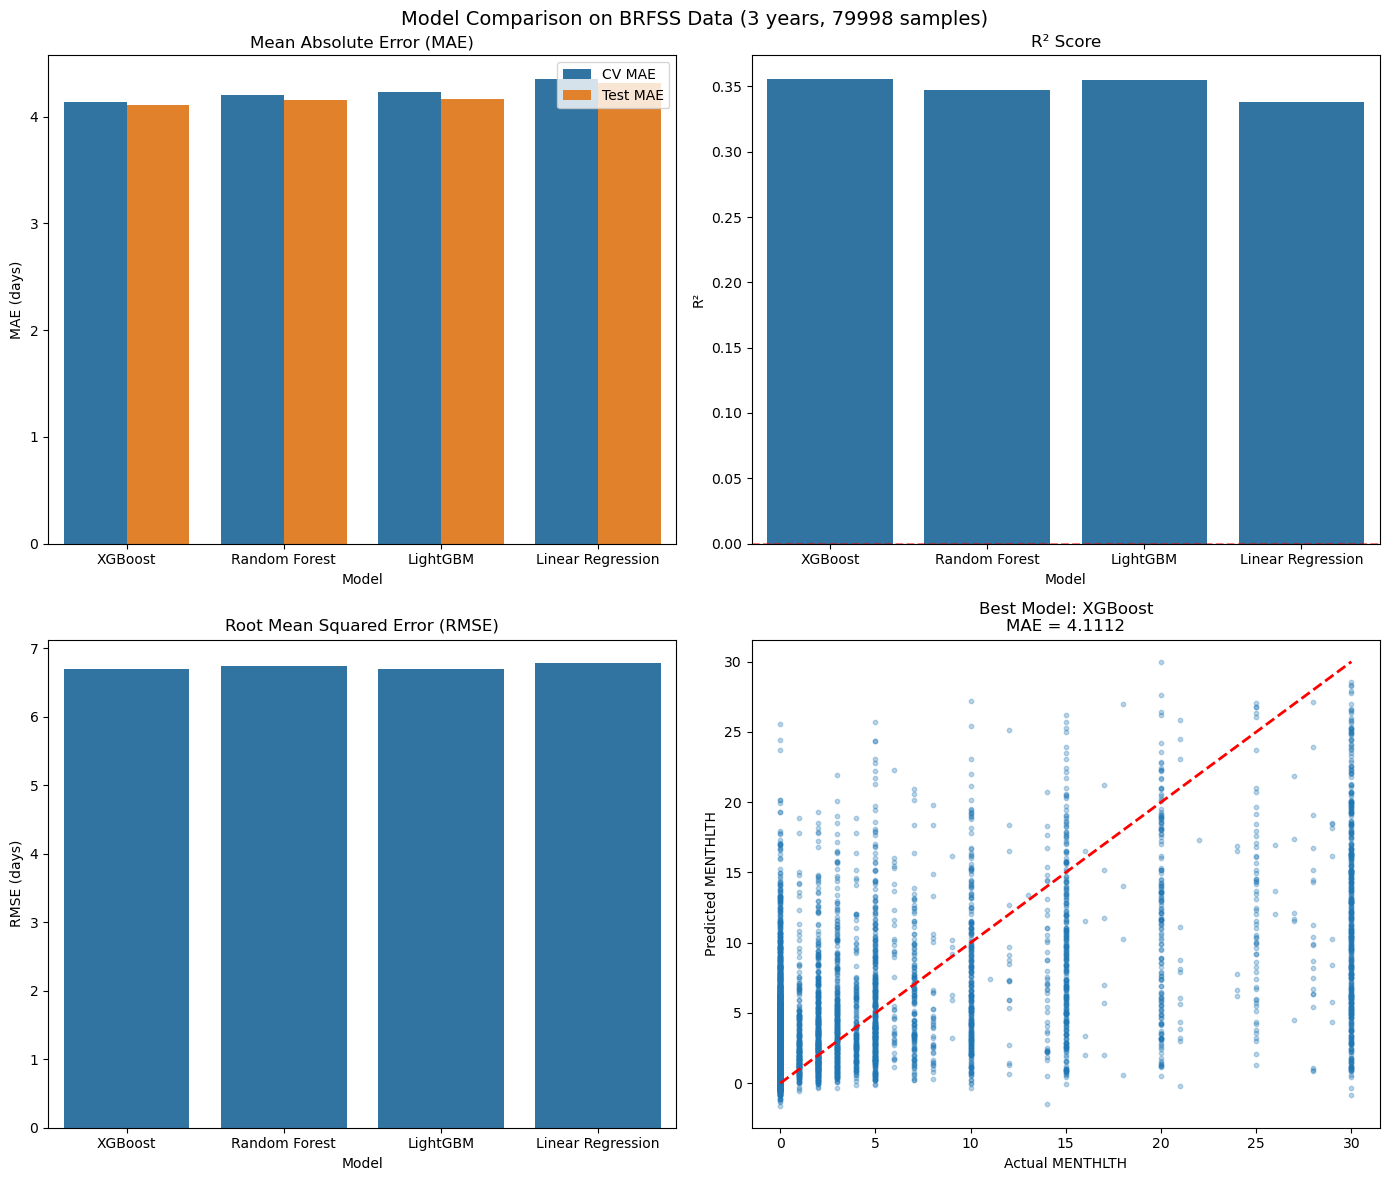


FEATURE IMPORTANCE (Top 15)

XGBoost Feature Importances:
 Feature  Importance
ADDEPEV3    0.316843
  DECIDE    0.212313
 _RFHLTH    0.055435
PHYSHLTH    0.053330
EMTSUPRT    0.042468
SDHBILLS    0.031987
MEDCOST1    0.025176
 GENHLTH    0.023816
  _AGE80    0.021585
SDHFOOD1    0.018784
DIFFALON    0.018553
SDHUTILS    0.013461
SDHTRNSP    0.011074
SDHEMPLY    0.010685
_SMOKER3    0.008928

Random Forest Feature Importances:
 Feature  Importance
ADDEPEV3    0.335057
  DECIDE    0.115394
PHYSHLTH    0.103304
EMTSUPRT    0.076927
  _AGE80    0.071546
     BMI    0.047038
  _STATE    0.028261
 GENHLTH    0.015532
_SMOKER3    0.012144
DROCDY4_    0.011801
 MARITAL    0.011359
 ALCDAY4    0.011093
SDHFOOD1    0.011007
 INCOME3    0.009878
   EDUCA    0.009391

LightGBM Feature Importances:
 Feature  Importance
  _AGE80        1715
     BMI        1574
PHYSHLTH        1289
EMTSUPRT        1061
  _STATE         896
 GENHLTH         657
SDHFOOD1         450
   EDUCA         448
 ALCDAY4     

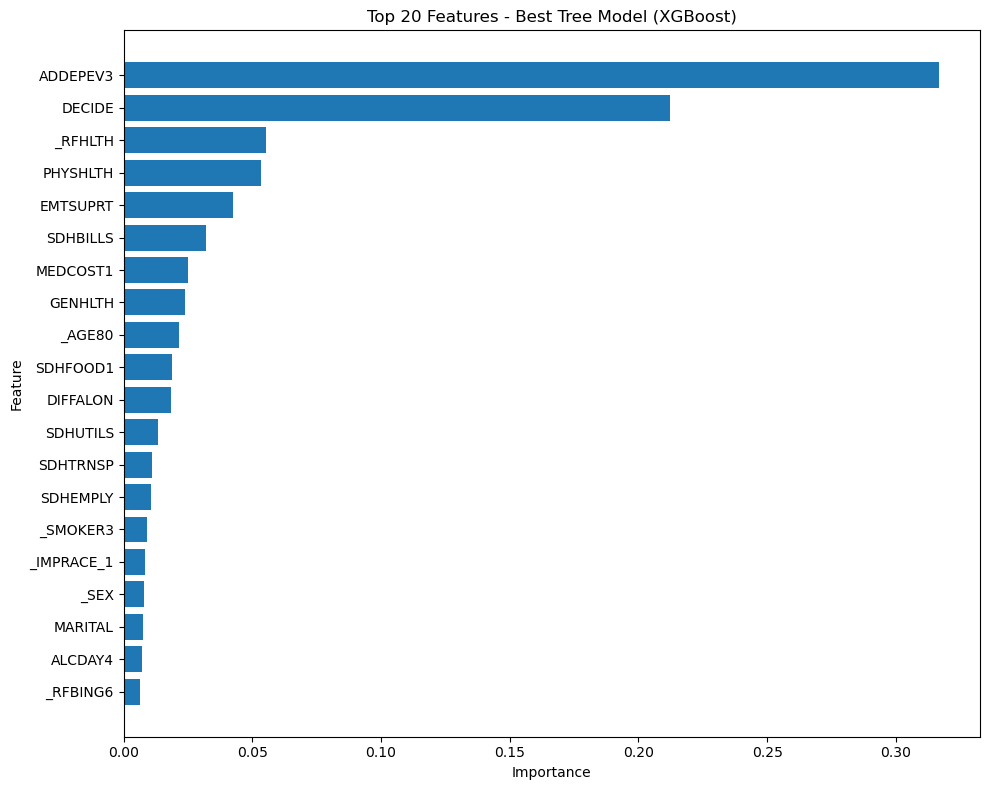


TRAINING COMPLETE


In [4]:
models = {
    'XGBoost': {
        'model': XGBRegressor(random_state=random_state, n_jobs=-1, verbosity=0),
        'use_scaled': False,
        'params': {
            'n_estimators': [650, 700],
            'max_depth': [2, 3],
            'learning_rate': [0.02, 0.25],
            'subsample': [0.7, 0.8],
            'colsample_bytree': [0.7],
            'min_child_weight': [3],
            'reg_alpha': [0.1],
            'reg_lambda': [0.1]
        }
    },

    'Random Forest': {
        'model': RandomForestRegressor(random_state=random_state, n_jobs=-1),
        'use_scaled': False,
        'params': {
            'n_estimators': [700, 750],
            'max_depth': [8, 10],
            'min_samples_split': [2],
            'min_samples_leaf': [6]
        }
    },
    'LightGBM': {
        'model': LGBMRegressor(random_state=random_state, n_jobs=-1, verbose=-1),
        'use_scaled': False,
        'params': {
            'n_estimators': [300, 500, 700],
            'max_depth': [3, 5, 7, -1],
            'learning_rate': [0.02, 0.05, 0.1],
        }
    },
    'Linear Regression': {
        'model': LinearRegression(),
        'use_scaled': True,
        'params': {}
    }
}

# ============================================================
# Train, Tune, and Evaluate Each Model
# ============================================================

results = []
best_models = {}

print("\n" + "="*70)
print("MODEL TRAINING AND EVALUATION")
print("="*70)

for name, config in models.items():
    print(f"\n{'='*60}")
    print(f"Training: {name}")
    print('='*60)
    
    # Select features
    if config['use_scaled']:
        X_train_use = X_train_scaled
        X_test_use = X_test_scaled
    else:
        X_train_use = X_train
        X_test_use = X_test
    
    # Use RandomizedSearchCV for large grids (faster)
    print("Hyperparameter tuning with RandomizedSearchCV...")
    
    if len(config['params']) > 0:
        # Random search for large grids
        if len(config['params']) > 10:
            random_search = RandomizedSearchCV(
                estimator=config['model'],
                param_distributions=config['params'],
                n_iter=20,  # Try 20 random combinations
                cv=5,
                scoring='neg_mean_absolute_error',
                n_jobs=-1,
                verbose=0,
                random_state=random_state
            )
            random_search.fit(X_train_use, y_train)
            best_model = random_search.best_estimator_
            best_params = random_search.best_params_
        else:
            # Grid search for smaller grids
            grid_search = GridSearchCV(
                estimator=config['model'],
                param_grid=config['params'],
                cv=5,
                scoring='neg_mean_absolute_error',
                n_jobs=-1,
                verbose=0
            )
            grid_search.fit(X_train_use, y_train)
            best_model = grid_search.best_estimator_
            best_params = grid_search.best_params_
    else:
        # No hyperparameters to tune
        best_model = config['model']
        best_params = {}
        best_model.fit(X_train_use, y_train)
    
    print(f"Best parameters: {best_params}")
    
    # Cross-validation score
    cv_scores = cross_val_score(
        best_model, X_train_use, y_train,
        cv=5, scoring='neg_mean_absolute_error'
    )
    cv_mae = -cv_scores.mean()
    print(f"Cross-Validation MAE: {cv_mae:.4f} (+/- {cv_scores.std():.4f})")
    
    # Predictions on test set
    y_pred = best_model.predict(X_test_use)
    
    # Evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    print(f"\nTest Set Performance:")
    print(f"  MAE:  {mae:.4f}")
    print(f"  RMSE: {rmse:.4f}")
    print(f"  R²:   {r2:.4f}")
    
    # Store results
    result = {
        'Model': name,
        'Best Params': best_params,
        'CV MAE': cv_mae,
        'Test MAE': mae,
        'Test RMSE': rmse,
        'Test R²': r2,
        'Model Object': best_model
    }
    results.append(result)
    best_models[name] = best_model

# ============================================================
# Results Summary
# ============================================================
print("\n" + "="*70)
print("RESULTS SUMMARY")
print("="*70)

results_df = pd.DataFrame([
    {
        'Model': r['Model'],
        'CV MAE': r['CV MAE'],
        'Test MAE': r['Test MAE'],
        'Test RMSE': r['Test RMSE'],
        'Test R²': r['Test R²']
    }
    for r in results
])

print(results_df.to_string(index=False))

# Sort by Test MAE
best_model = min(results, key=lambda x: x['Test MAE'])
print(f"\nBest Model: {best_model['Model']} (MAE: {best_model['Test MAE']:.4f})")

# ============================================================
# Visualize Results
# ============================================================
os.makedirs('plots', exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle(f'Model Comparison on BRFSS Data ({n_years} years, {len(df)} samples)', fontsize=14)

# Plot 1: MAE Comparison
ax1 = axes[0, 0]
metrics = results_df.melt(
    id_vars=['Model'],
    value_vars=['CV MAE', 'Test MAE'],
    var_name='Metric', value_name='MAE'
)
sns.barplot(data=metrics, x='Model', y='MAE', hue='Metric', ax=ax1)
ax1.set_title('Mean Absolute Error (MAE)')
ax1.set_ylabel('MAE (days)')
ax1.legend()

# Plot 2: R² Comparison
ax2 = axes[0, 1]
sns.barplot(data=results_df, x='Model', y='Test R²', ax=ax2)
ax2.set_title('R² Score')
ax2.set_ylabel('R²')
ax2.axhline(y=0, color='red', linestyle='--', alpha=0.5)

# Plot 3: RMSE Comparison
ax3 = axes[1, 0]
sns.barplot(data=results_df, x='Model', y='Test RMSE', ax=ax3)
ax3.set_title('Root Mean Squared Error (RMSE)')
ax3.set_ylabel('RMSE (days)')

# Plot 4: Actual vs Predicted for Best Model
best_model_obj = best_model['Model Object']
best_model_name = best_model['Model']

if models[best_model_name]['use_scaled']:
    y_pred_best = best_model_obj.predict(X_test_scaled)
else:
    y_pred_best = best_model_obj.predict(X_test)

ax4 = axes[1, 1]
ax4.scatter(y_test, y_pred_best, alpha=0.3, s=10)
ax4.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
ax4.set_xlabel('Actual MENTHLTH')
ax4.set_ylabel('Predicted MENTHLTH')
ax4.set_title(f'Best Model: {best_model_name}\nMAE = {best_model["Test MAE"]:.4f}')

plt.tight_layout()
plt.savefig('plots/model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================
# Feature Importance (for tree-based models)
# ============================================================
print("\n" + "="*70)
print("FEATURE IMPORTANCE (Top 15)")
print("="*70)

for r in results:
    model = r['Model Object']
    model_name = r['Model']
    if hasattr(model, 'feature_importances_'):
        print(f"\n{model_name} Feature Importances:")
        importances = model.feature_importances_
        feature_imp = pd.DataFrame({
            'Feature': X.columns,
            'Importance': importances
        }).sort_values('Importance', ascending=False).head(15)
        print(feature_imp.to_string(index=False))
    elif hasattr(model, 'coef_'):
        print(f"\n{model_name} Coefficients (Top 15 absolute):")
        coefs = model.coef_.flatten() if len(model.coef_.shape) > 1 else model.coef_
        coef_imp = pd.DataFrame({
            'Feature': X.columns,
            'Coefficient': coefs
        })
        coef_imp['Abs'] = np.abs(coef_imp['Coefficient'])
        coef_imp = coef_imp.sort_values('Abs', ascending=False).head(15)
        print(coef_imp[['Feature', 'Coefficient']].to_string(index=False))
    else:
        print(f"\n{model_name} does not provide feature importance.")

# ============================================================
# Save Best Model and Results
# ============================================================
os.makedirs('models', exist_ok=True)

# Save best model
best_model = min(results, key=lambda x: x['Test MAE'])
joblib.dump(best_model['Model Object'], f'models/best_model_{best_model["Model"]}.pkl')
print(f"\nBest model ({best_model['Model']}) saved to models/best_model_{best_model['Model']}.pkl")

# Save scaler
if any(r['Model'] in ['Ridge', 'Lasso', 'Poisson Regression'] for r in results):
    joblib.dump(scaler, 'models/scaler.pkl')
    print("Scaler saved to models/scaler.pkl")

# Save results to CSV
results_df.to_csv('models/model_results.csv', index=False)
print("Results saved to models/model_results.csv")

# ============================================================
# Feature Importance Visualization (Top 20) - for best tree model
# ============================================================
best_tree_model = next((r for r in results if hasattr(r['Model Object'], 'feature_importances_')), None)

if best_tree_model:
    importances = best_tree_model['Model Object'].feature_importances_
    feature_imp = pd.DataFrame({
        'Feature': X.columns,
        'Importance': importances
    }).sort_values('Importance', ascending=True).tail(20)

    plt.figure(figsize=(10, 8))
    plt.barh(feature_imp['Feature'], feature_imp['Importance'])
    plt.xlabel('Importance')
    plt.ylabel('Feature')
    plt.title(f'Top 20 Features - Best Tree Model ({best_tree_model["Model"]})')
    plt.tight_layout()
    plt.savefig('plots/best_model_feature_importance.png', dpi=150, bbox_inches='tight')
    plt.show()

print("\n" + "="*70)
print("TRAINING COMPLETE")
print("="*70)

---

### Deep Learning Models

In [4]:
# Use all samples
X_train, X_test, y_train, y_test = train_test_split(
    X[:deep_models_n_samples], y[:deep_models_n_samples],
    test_size=test_size,
    random_state=random_state
)

model = TabICLRegressor(
    device='cpu',
    random_state=42,
    kv_cache=False,
    n_estimators=8
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"TabICL Test MAE: {mae:.4f}")
print(f"TabICL Test R²:  {r2:.4f}")

TabICL Test MAE: 4.0745
TabICL Test R²:  0.3587


---